# M9b · Cross-dataset test on UADFV (no training)

**Question.** Does the ranking seen on DFD (M8b: GBLA λ=0.01 96.71 vs LNCLIP-DF reproduction 95.88) hold on a second dataset?

**Protocol (same as M8b and LNCLIP-DF / GenD, Yermakov et al., WACV 2026).** Train on FF++ c23 (real + DF, F2F, FS, NT; FaceShifter never seen), test on UADFV: 49 real + 49 fake videos. Video score = mean of the 32 frame fake-probabilities; metric = video AUC. Paper reference: **GenD (CLIP ViT-L/14) UADFV video AUC 99.2** (Table 4, mean of 5 seeds).

**Models.** The same 9 checkpoints as M8b: frozen CLIP ViT-L/14 + trained LayerNorms + linear head on the L2-normalized CLS token, **104,450 trainable parameters at test time**, all trained on the same four FF++ generators, seed 0, 10 epochs. None is retrained here.

| key | model | from |
|---|---|---|
| `m1` | LNCLIP-DF reproduction (paper recipe, mixed batches) | M1 |
| `lam_inf` | pooled ERM with GBLA's batching (one generator per batch); λ = ∞ | M4 |
| `lam_1`, `lam_0.1`, **`lam_0.01`**, `lam_0.001`, `lam_0` | GBLA θ_s at each λ (λ = 0.01 is our chosen setting) | M4 |
| `uniform`, `fisher` | average / Fisher merge of the four single-generator models | M6 (hold-FSh fold) |

**Data.** Crops from M9a (`faces_uadfv`, `index/uadfv.csv`): 3,136 crops, made exactly like the FF++ and DFD crops (32 frames, JPEG q95 4:2:0 round trip, MTCNN, 1.3× square, 224 px). All 98 videos extracted, 21 frames without a face, 3.2% of frames with ≥2 faces.

**What to expect.** UADFV is small and easy (the paper is at 99.2), so all models may sit near the ceiling. With 49 pairs the intervals are wide; differences of a few tenths will not be significant. The useful outputs are: does any model break down, and is the ranking the same as on DFD.

**Statistics.** 95% intervals from a bootstrap that resamples the **49 real/fake pairs** (a real video and the fake made from it stay together), paired across models. Note: some people appear in more than one UADFV pair (e.g. pairs 0000 and 0032 both show the same politician), so pairs are not fully independent and the intervals are, if anything, too narrow. Single seed per model (paper: 5 seeds).

| Section | What it does | Run time |
|---|---|---|
| 1 | settings, imports | seconds |
| 2 | model, parameter report, load checks against saved FF++ predictions | ~3 min |
| 3 | load the UADFV crops into RAM | seconds |
| 4 | predict every model (resumable) | seconds per model |
| 5 | main table vs paper, bootstrap intervals, paired differences | ~1 min |
| 6 | pair-level check: is each fake scored above its own real video | seconds |
| 7 | λ curve and cross-dataset summary (FF++ unseen, DFD, UADFV) | seconds |
| 8 | single-face sensitivity, ROC curves, summary | seconds |

## 1. Setup

### 1.1 Settings

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
RUNS_ROOT = DATA_ROOT / "runs"
FACES_UADFV = DATA_ROOT / "faces_uadfv"
UADFV_INDEX = DATA_ROOT / "index" / "uadfv.csv"
FACES_FF = DATA_ROOT / "faces"
M8B_DIR = RUNS_ROOT / "m8b"
M9B_DIR = RUNS_ROOT / "m9b"

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
SEED = 0
EPOCH = 10
EVAL_BATCH = 256
LOAD_THREADS = 16
N_BOOT = 2000
N_LOAD_CHECK = 256        # FF++ test crops used to check that each checkpoint loads correctly

PAPER_UADFV_VIDEO_AUC = 99.2   # GenD (CLIP ViT-L/14), Table 4, mean of 5 seeds
PAPER_DFD_VIDEO_AUC = 96.4

M1_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-DF-F2F-FS-NT_seed{SEED}"
M4_DIR = RUNS_ROOT / "m4"
M6_MERGES = RUNS_ROOT / "m6" / "merges"


def m4_run(tag):
    return M4_DIR / f"gbla_lam{tag}_{ARCH}_seed{SEED}"


# key: (display name, checkpoint kind, checkpoint path, saved FF++ test predictions or None)
MODELS = {
    "m1": ("LNCLIP-DF repro (M1)", "state", M1_DIR / f"epoch_{EPOCH:02d}.pt", M1_DIR / f"test_predictions_epoch{EPOCH:02d}.csv"),
    "lam_inf": ("pooled, λ=∞ (M4)", "gbla", m4_run("inf") / f"epoch_{EPOCH:02d}.pt", m4_run("inf") / "test_predictions.csv"),
    "lam_1": ("GBLA λ=1", "gbla", m4_run("1") / f"epoch_{EPOCH:02d}.pt", m4_run("1") / "test_predictions.csv"),
    "lam_0.1": ("GBLA λ=0.1", "gbla", m4_run("0.1") / f"epoch_{EPOCH:02d}.pt", m4_run("0.1") / "test_predictions.csv"),
    "lam_0.01": ("GBLA λ=0.01 (ours)", "gbla", m4_run("0.01") / f"epoch_{EPOCH:02d}.pt", m4_run("0.01") / "test_predictions.csv"),
    "lam_0.001": ("GBLA λ=0.001", "gbla", m4_run("0.001") / f"epoch_{EPOCH:02d}.pt", m4_run("0.001") / "test_predictions.csv"),
    "lam_0": ("GBLA λ=0", "gbla", m4_run("0") / f"epoch_{EPOCH:02d}.pt", m4_run("0") / "test_predictions.csv"),
    "uniform": ("uniform merge (M6)", "flat", M6_MERGES / "hold-FSh_uniform.pt", None),
    "fisher": ("Fisher merge (M6)", "flat", M6_MERGES / "hold-FSh_fisher.pt", None),
}
M6_FSH_VIDEO_AUC = {"uniform": 81.43, "fisher": 88.99}   # M6 LOGO table, FaceShifter held out
M1_FSH_VIDEO_AUC = 88.19                                   # M1 epoch 10, recomputed in M8b
MAIN = ["m1", "lam_inf", "lam_0.01"]
OURS = "lam_0.01"

assert UADFV_INDEX.exists(), f"run M9a first: {UADFV_INDEX}"
M9B_DIR.mkdir(parents=True, exist_ok=True)
missing = [k for k, (_, _, path, _) in MODELS.items() if not path.exists()]
for k in missing:
    print(f"checkpoint not found, skipped: {k} -> {MODELS[k][2]}")
MODELS = {k: v for k, v in MODELS.items() if k not in missing}
assert all(k in MODELS for k in MAIN), "a main model is missing"
print("models:", list(MODELS))

models: ['m1', 'lam_inf', 'lam_1', 'lam_0.1', 'lam_0.01', 'lam_0.001', 'lam_0', 'uniform', 'fisher']


In [2]:
# 1.2 Imports and environment
import json, random, time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda"
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)
display(pd.Series({"torch": torch.__version__, "open_clip": open_clip.__version__,
                   "GPU": torch.cuda.get_device_name(0)}, name="value").to_frame())

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB


## 2. Model and load checks

### 2.1 Detector (as in M1/M4/M8b) and parameter report

In [3]:
# 2.1 Detector and parameter report
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE).eval()
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)
TOTAL = sum(p.numel() for p in model.parameters())
param_report = {"total": TOTAL, "trainable (deployed)": P, "frozen": TOTAL - P,
                "trainable %": round(100 * P / TOTAL, 4)}
display(pd.Series(param_report, name="parameters").to_frame())
assert P == 104_450, P


@torch.no_grad()
def set_flat(theta):
    theta = theta.to(DEVICE).float()
    assert theta.numel() == P, (theta.numel(), P)
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p).to(p.dtype))
        offset += n


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def load_theta(kind, path):
    obj = load(path)
    if kind == "state":
        state = obj.get("trainable", obj)
        return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES])
    if kind == "gbla":
        return obj.get("gbla", obj)["theta_s"].float()
    if kind == "flat":
        return obj["theta"].float()
    raise ValueError(kind)


THETAS = {k: load_theta(kind, path) for k, (_, kind, path, _) in MODELS.items()}
print({k: f"{v.numel():,}" for k, v in THETAS.items()})

,parameters
total,3.031818e+08
trainable (deployed),1.044500e+05
frozen,3.030774e+08
trainable %,3.450000e-02


{'m1': '104,450', 'lam_inf': '104,450', 'lam_1': '104,450', 'lam_0.1': '104,450', 'lam_0.01': '104,450', 'lam_0.001': '104,450', 'lam_0': '104,450', 'uniform': '104,450', 'fisher': '104,450'}


In [4]:
# 2.2 Prediction helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("RGB"))


def load_images(paths, desc):
    images = np.empty((len(paths), 224, 224, 3), dtype=np.uint8)

    def fill(i):
        images[i] = read_rgb(paths[i])

    with ThreadPoolExecutor(LOAD_THREADS) as pool:
        list(tqdm(pool.map(fill, range(len(paths)), chunksize=64), total=len(paths), desc=desc))
    return images


@torch.no_grad()
def predict(theta, images, desc="predict"):
    set_flat(theta)
    probs = []
    for s in tqdm(range(0, len(images), EVAL_BATCH), desc=desc, leave=False):
        x = torch.from_numpy(images[s:s + EVAL_BATCH]).to(DEVICE, non_blocking=True)
        x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits, _ = model(x)
        probs.append(logits.float().softmax(1)[:, 1].cpu())
    return torch.cat(probs).numpy()


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def average_precision(labels, scores):
    order = np.argsort(-np.asarray(scores), kind="stable")
    y = np.asarray(labels)[order]
    precision = np.cumsum(y) / np.arange(1, len(y) + 1)
    return float((precision * y).sum() / y.sum())


def roc_points(labels, scores):
    order = np.argsort(-np.asarray(scores), kind="stable")
    y = np.asarray(labels)[order]
    tpr = np.concatenate([[0], np.cumsum(y) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y) / (1 - y).sum()])
    return fpr, tpr


def eer(labels, scores):
    fpr, tpr = roc_points(labels, scores)
    i = np.argmin(np.abs((1 - tpr) - fpr))
    return float((fpr[i] + 1 - tpr[i]) / 2)

### 2.3 Load check: reproduce saved FF++ results

Same check as M8b. Models with saved per-crop FF++ test predictions: recompute 256 random crops, max |difference| must stay below 0.05. Models without them (M1 epoch 10 and the M6 merges): recompute the FF++ FaceShifter video AUC and compare with the reference (M1 88.19 from M8b, uniform 81.43, Fisher 88.99; tolerance 0.3). The notebook stops if a checkpoint was loaded wrongly.

In [5]:
# 2.3 Load check
FSH_REFERENCE = {"m1": M1_FSH_VIDEO_AUC, **M6_FSH_VIDEO_AUC}
ff_index = pd.read_csv(DATA_ROOT / "index" / "ffpp_c23.csv")
ff_fsh = ff_index[(ff_index.split == "test") & ff_index.generator.isin(["original", "FaceShifter"])].reset_index(drop=True)
ff_fsh_images = None
check_rows, FF_FSH_RECOMPUTED = [], {}
for k, (name, _, _, ref_path) in MODELS.items():
    if ref_path is None or not ref_path.exists():
        if ff_fsh_images is None:
            ff_fsh_images = load_images([str(FACES_FF / p) for p in ff_fsh.path], desc="FF++ test real+FSh")
        pred = ff_fsh.assign(prob=predict(THETAS[k], ff_fsh_images, desc=f"FF++ FSh {k}"))
        vid = pred.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        FF_FSH_RECOMPUTED[k] = 100 * auc(vid.label, vid.prob)
        expected = FSH_REFERENCE.get(k)
        check_rows.append({"model": k, "crops": len(ff_fsh), "FF++ FSh video AUC": round(FF_FSH_RECOMPUTED[k], 2),
                           "expected": expected,
                           "ok": bool(expected is None or abs(FF_FSH_RECOMPUTED[k] - expected) < 0.3)})
        continue
    ref = pd.read_csv(ref_path).sample(N_LOAD_CHECK, random_state=SEED)
    imgs = load_images([str(FACES_FF / p) for p in ref.path], desc=f"check {k}")
    diff = np.abs(predict(THETAS[k], imgs, desc=f"check {k}") - ref.prob.values)
    check_rows.append({"model": k, "crops": len(ref), "max |diff|": round(float(diff.max()), 4),
                       "mean |diff|": round(float(diff.mean()), 5), "ok": bool(diff.max() < 0.05)})
load_check = pd.DataFrame(check_rows)
display(load_check)
load_check.to_csv(M9B_DIR / "load_check.csv", index=False)
assert load_check.ok.all(), "a checkpoint does not reproduce its FF++ results"
del ff_fsh_images

check lam_0: 100%|██████████| 256/256 [00:00<00:00, 1201.14it/s]
                                                                 

,model,crops,FF++ FSh video AUC,expected,ok,max |diff|,mean |diff|
0,m1,8960,88.19,88.19,True,NaN,NaN
1,lam_inf,256,NaN,NaN,True,0.0,0.0
2,lam_1,256,NaN,NaN,True,0.0,0.0
3,lam_0.1,256,NaN,NaN,True,0.0,0.0
4,lam_0.01,256,NaN,NaN,True,0.0,0.0
5,lam_0.001,256,NaN,NaN,True,0.0,0.0
6,lam_0,256,NaN,NaN,True,0.0,0.0
7,uniform,8960,81.43,81.43,True,NaN,NaN
8,fisher,8960,88.99,88.99,True,NaN,NaN


## 3. UADFV crops into RAM

3,136 crops × 224 × 224 × 3 bytes ≈ 0.47 GB.

In [6]:
# 3. Load UADFV crops
index = pd.read_csv(UADFV_INDEX, dtype={"video_id": str, "pair_id": str})
videos = index.groupby("video_id", as_index=False).agg(label=("label", "first"), pair_id=("pair_id", "first"),
                                                       crops=("path", "size"))
print(f"crops: {len(index):,}   videos: real {(videos.label == 0).sum()}, fake {(videos.label == 1).sum()}   "
      f"pairs: {videos.pair_id.nunique()}   crops per video: {videos.crops.min()}-{videos.crops.max()}")
assert (videos.label == 0).sum() == 49 and (videos.label == 1).sum() == 49

UADFV_IMAGES = load_images([str(FACES_UADFV / p) for p in index.path], desc="UADFV crops")
print(f"loaded {UADFV_IMAGES.nbytes / 1e9:.2f} GB")

crops: 3,136   videos: real 49, fake 49   pairs: 49   crops per video: 32-32


UADFV crops: 100%|██████████| 3136/3136 [00:05<00:00, 564.79it/s]

loaded 0.47 GB


## 4. Predict every model (resumable)

Frame probabilities go to `runs/m9b/pred_<model>.csv` (same row order as the index). Existing files are reused.

In [7]:
# 4. Predict
FRAME_PROBS = {}
for k, (name, *_ ) in MODELS.items():
    path = M9B_DIR / f"pred_{k}.csv"
    if path.exists():
        saved = pd.read_csv(path)
        if len(saved) == len(index) and (saved.path.values == index.path.values).all():
            FRAME_PROBS[k] = saved.prob.values
            print(f"{k}: reused {path.name}")
            continue
    t0 = time.time()
    probs = predict(THETAS[k], UADFV_IMAGES, desc=k)
    pd.DataFrame({"video_id": index.video_id, "frame_idx": index.frame_idx, "path": index.path, "prob": probs}).to_csv(path, index=False)
    FRAME_PROBS[k] = probs
    print(f"{k}: predicted in {time.time() - t0:.0f} s")

m1: predicted in 5 s


lam_inf: predicted in 5 s


lam_1: predicted in 5 s


lam_0.1: predicted in 5 s


lam_0.01: predicted in 5 s


lam_0.001: predicted in 5 s


lam_0: predicted in 5 s


uniform: predicted in 5 s


fisher: predicted in 5 s


## 5. Results on UADFV

### 5.1 Main table

Video score = mean frame probability (paper protocol). `real acc` / `fake acc` use threshold 0.5. CI = 95% pair-cluster bootstrap.

In [8]:
# 5.1 Main table
def video_scores(k, frame_mask=None):
    """Mean frame probability per video (videos order). frame_mask: use only these frames, all frames if a video has none."""
    df = pd.DataFrame({"video_id": index.video_id, "prob": FRAME_PROBS[k]})
    allv = df.groupby("video_id").prob.mean()
    if frame_mask is not None:
        allv = df[frame_mask].groupby("video_id").prob.mean().reindex(allv.index).fillna(allv)
    return allv.reindex(videos.video_id).values


VIDEO_SCORES = {k: video_scores(k) for k in MODELS}
y_vid = videos.label.values

pairs = sorted(videos.pair_id.unique())
rows_of_pair = {a: np.flatnonzero(videos.pair_id.values == a) for a in pairs}
rng = np.random.default_rng(SEED)
BOOT_ROWS = [np.concatenate([rows_of_pair[a] for a in rng.choice(pairs, len(pairs), replace=True)]) for _ in range(N_BOOT)]


def boot_auc(scores):
    return np.array([auc(y_vid[rows], scores[rows]) for rows in BOOT_ROWS])


BOOT = {k: boot_auc(VIDEO_SCORES[k]) for k in tqdm(MODELS, desc="bootstrap")}

rows = []
for k, (name, *_ ) in MODELS.items():
    s = VIDEO_SCORES[k]
    lo, hi = np.nanpercentile(BOOT[k], [2.5, 97.5]) * 100
    rows.append({"model": name, "key": k,
                 "video AUC": 100 * auc(y_vid, s), "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                 "frame AUC": 100 * auc(index.label.values, FRAME_PROBS[k]),
                 "video AP": 100 * average_precision(y_vid, s), "video EER": 100 * eer(y_vid, s),
                 "real acc": 100 * float((s[y_vid == 0] <= 0.5).mean()),
                 "fake acc": 100 * float((s[y_vid == 1] > 0.5).mean())})
rows.append({"model": "GenD (CLIP) paper, 5 seeds", "key": "paper", "video AUC": PAPER_UADFV_VIDEO_AUC})
main_table = pd.DataFrame(rows).set_index("model")
display(main_table.round(2))
main_table.to_csv(M9B_DIR / "uadfv_main_table.csv")
print(f"\nall models: {P:,} trainable parameters at test time ({param_report['trainable %']}% of {TOTAL:,})")

bootstrap: 100%|██████████| 9/9 [00:01<00:00,  4.92it/s]


,key,video AUC,95% CI,frame AUC,video AP,video EER,real acc,fake acc
model,,,,,,,,
LNCLIP-DF repro (M1),m1,99.25,"[97.46, 100.00]",97.86,99.40,4.08,95.92,97.96
"pooled, λ=∞ (M4)",lam_inf,99.38,"[98.08, 100.00]",97.96,99.45,4.08,93.88,95.92
GBLA λ=1,lam_1,99.33,"[98.00, 100.00]",98.01,99.41,4.08,85.71,97.96
GBLA λ=0.1,lam_0.1,99.50,"[98.33, 100.00]",98.01,99.56,4.08,93.88,95.92
GBLA λ=0.01 (ours),lam_0.01,99.63,"[98.83, 100.00]",97.97,99.64,4.08,89.80,100.00
GBLA λ=0.001,lam_0.001,99.71,"[98.92, 100.00]",98.04,99.73,4.08,100.00,95.92
GBLA λ=0,lam_0,99.58,"[98.50, 100.00]",97.81,99.62,4.08,100.00,95.92
uniform merge (M6),uniform,99.13,"[97.25, 100.00]",97.40,99.31,4.08,97.96,95.92
Fisher merge (M6),fisher,98.83,"[96.25, 100.00]",97.16,99.17,4.08,79.59,97.96



all models: 104,450 trainable parameters at test time (0.0345% of 303,181,826)


### 5.2 Paired differences (ours − other)

Same bootstrap resamples for both models, so the interval is for the difference itself. `P(diff > 0)` = share of resamples where GBLA λ=0.01 is better.

In [9]:
# 5.2 Paired differences
diff_rows = []
for k in MODELS:
    if k == OURS:
        continue
    d = (BOOT[OURS] - BOOT[k]) * 100
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    diff_rows.append({"ours − ": MODELS[k][0],
                      "video AUC diff": 100 * (auc(y_vid, VIDEO_SCORES[OURS]) - auc(y_vid, VIDEO_SCORES[k])),
                      "95% CI": f"[{lo:+.2f}, {hi:+.2f}]", "P(diff > 0)": float(np.nanmean(d > 0))})
diffs = pd.DataFrame(diff_rows).set_index("ours − ")
display(diffs.round(3))
diffs.to_csv(M9B_DIR / "uadfv_paired_differences.csv")

,video AUC diff,95% CI,P(diff > 0)
ours −,,,
LNCLIP-DF repro (M1),0.375,"[-0.50, +1.92]",0.640
"pooled, λ=∞ (M4)",0.250,"[-0.29, +1.25]",0.715
GBLA λ=1,0.292,"[-0.25, +1.33]",0.772
GBLA λ=0.1,0.125,"[-0.37, +1.04]",0.562
GBLA λ=0.001,-0.083,"[-0.62, +0.62]",0.330
GBLA λ=0,0.042,"[-0.54, +1.00]",0.482
uniform merge (M6),0.500,"[-0.37, +2.12]",0.706
Fisher merge (M6),0.791,"[-0.42, +3.17]",0.690


## 6. Pair-level check

Every UADFV fake was made from one real video. For each of the 49 pairs we ask: is the fake scored higher than its own real video? `pairs correct` counts them; `mean margin` is the average of (fake score − real score). This is a stricter, identity-controlled view than AUC, which also compares a fake against other people's real videos. The table lists the pairs that any main model gets wrong.

In [10]:
# 6. Pair-level check
vs = {k: pd.Series(VIDEO_SCORES[k], index=videos.video_id) for k in MODELS}
real_of = videos[videos.label == 0].set_index("pair_id").video_id
fake_of = videos[videos.label == 1].set_index("pair_id").video_id
pair_rows, margins = [], {}
for k, (name, *_ ) in MODELS.items():
    m = pd.Series({p: vs[k][fake_of[p]] - vs[k][real_of[p]] for p in pairs})
    margins[k] = m
    pair_rows.append({"model": name, "pairs correct": f"{int((m > 0).sum())}/{len(m)}",
                      "mean margin": float(m.mean()), "min margin": float(m.min())})
pair_table = pd.DataFrame(pair_rows).set_index("model")
display(pair_table.round(3))
pair_table.to_csv(M9B_DIR / "uadfv_pair_check.csv")

wrong = sorted({p for k in MAIN for p in pairs if margins[k][p] <= 0})
if wrong:
    detail = pd.DataFrame({MODELS[k][0]: margins[k][wrong] for k in MAIN})
    detail.insert(0, "real score (ours)", [vs[OURS][real_of[p]] for p in wrong])
    detail.insert(1, "fake score (ours)", [vs[OURS][fake_of[p]] for p in wrong])
    print("pairs with fake score <= real score for at least one main model (margins = fake − real):")
    display(detail.round(3))
else:
    print("every main model scores every fake above its own real video")

,pairs correct,mean margin,min margin
model,,,
LNCLIP-DF repro (M1),48/49,0.669,-0.023
"pooled, λ=∞ (M4)",48/49,0.662,-0.003
GBLA λ=1,48/49,0.676,-0.027
GBLA λ=0.1,48/49,0.712,-0.016
GBLA λ=0.01 (ours),49/49,0.677,0.027
GBLA λ=0.001,48/49,0.760,-0.012
GBLA λ=0,48/49,0.718,-0.015
uniform merge (M6),48/49,0.466,-0.011
Fisher merge (M6),48/49,0.385,-0.007


pairs with fake score <= real score for at least one main model (margins = fake − real):


,real score (ours),fake score (ours),LNCLIP-DF repro (M1),"pooled, λ=∞ (M4)",GBLA λ=0.01 (ours)
0043,0.509,0.536,-0.023,-0.003,0.027


## 7. Cross-dataset view

### 7.1 λ curve: FF++ unseen generator, DFD and UADFV

FF++ numbers are recomputed from each model's saved FF++ test predictions (FaceShifter for the merges and M1 come from 2.3). DFD numbers are read from M8b's main table.

,FF++ FaceShifter (unseen),DFD video AUC,UADFV video AUC,mean DFD + UADFV
model,,,,
LNCLIP-DF repro (M1),88.19,95.88,99.25,97.57
"pooled, λ=∞ (M4)",90.53,96.05,99.38,97.71
GBLA λ=1,92.06,96.40,99.33,97.87
GBLA λ=0.1,92.48,96.70,99.50,98.10
GBLA λ=0.01 (ours),92.91,96.71,99.63,98.17
GBLA λ=0.001,86.35,95.33,99.71,97.52
GBLA λ=0,80.04,94.43,99.58,97.01
uniform merge (M6),81.43,92.68,99.13,95.90
Fisher merge (M6),88.99,94.95,98.83,96.89


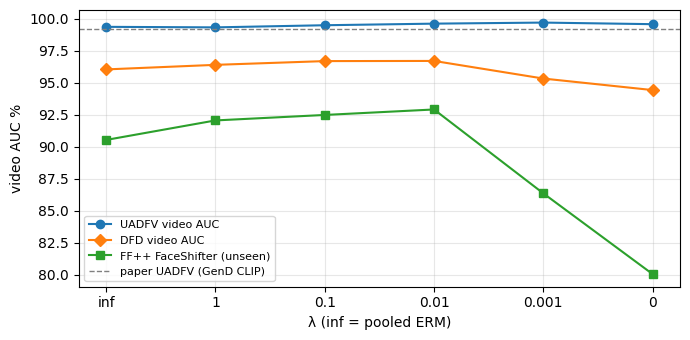

rank agreement DFD vs UADFV: Spearman 0.38 over 9 models; -0.14 over the 6 λ values


In [11]:
# 7.1 FF++ vs DFD vs UADFV per model
SEEN = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]


def ff_video_auc(pred, gens):
    sub = pred[pred.generator.isin(["original", *gens])]
    vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


dfd_table = pd.read_csv(M8B_DIR / "dfd_main_table.csv").set_index("key") if (M8B_DIR / "dfd_main_table.csv").exists() else None
cmp_rows = []
for k, (name, _, _, ref_path) in MODELS.items():
    row = {"model": name}
    if ref_path is not None and ref_path.exists():
        pred = pd.read_csv(ref_path)
        pred = pred[pred.split == "test"] if "split" in pred else pred
        row["FF++ FaceShifter (unseen)"] = ff_video_auc(pred, ["FaceShifter"])
    elif k in FF_FSH_RECOMPUTED:
        row["FF++ FaceShifter (unseen)"] = FF_FSH_RECOMPUTED[k]
    if dfd_table is not None and k in dfd_table.index:
        row["DFD video AUC"] = float(dfd_table.loc[k, "video AUC"])
    row["UADFV video AUC"] = 100 * auc(y_vid, VIDEO_SCORES[k])
    if "DFD video AUC" in row:
        row["mean DFD + UADFV"] = (row["DFD video AUC"] + row["UADFV video AUC"]) / 2
    cmp_rows.append(row)
cmp_rows.append({"model": "GenD (CLIP) paper, 5 seeds", "FF++ FaceShifter (unseen)": 86.6,
                 "DFD video AUC": PAPER_DFD_VIDEO_AUC, "UADFV video AUC": PAPER_UADFV_VIDEO_AUC,
                 "mean DFD + UADFV": (PAPER_DFD_VIDEO_AUC + PAPER_UADFV_VIDEO_AUC) / 2})
cross = pd.DataFrame(cmp_rows).set_index("model")
display(cross.round(2))
cross.to_csv(M9B_DIR / "cross_dataset_summary.csv")

lam_keys = [k for k in ["lam_inf", "lam_1", "lam_0.1", "lam_0.01", "lam_0.001", "lam_0"] if k in MODELS]
labels = [k.replace("lam_", "") for k in lam_keys]
fig, ax = plt.subplots(figsize=(7, 3.5))
for col, marker in [("UADFV video AUC", "o"), ("DFD video AUC", "D"), ("FF++ FaceShifter (unseen)", "s")]:
    if col in cross:
        ax.plot(labels, [cross.loc[MODELS[k][0], col] for k in lam_keys], marker=marker, label=col)
ax.axhline(PAPER_UADFV_VIDEO_AUC, ls="--", c="gray", lw=1, label="paper UADFV (GenD CLIP)")
ax.set_xlabel("λ (inf = pooled ERM)"); ax.set_ylabel("video AUC %"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M9B_DIR / "lambda_curve.png", dpi=150); plt.show()

if "DFD video AUC" in cross:
    sub = cross.loc[[MODELS[k][0] for k in MODELS]].dropna(subset=["DFD video AUC"])
    lam_sub = cross.loc[[MODELS[k][0] for k in lam_keys]]
    print(f"rank agreement DFD vs UADFV: Spearman {sub['DFD video AUC'].corr(sub['UADFV video AUC'], method='spearman'):.2f} "
          f"over {len(sub)} models; {lam_sub['DFD video AUC'].corr(lam_sub['UADFV video AUC'], method='spearman'):.2f} "
          f"over the {len(lam_keys)} λ values")

## 8. Sensitivity, ROC and summary

### 8.1 Single-face frames only

M9a found 99 of 3,136 frames (3.2%) with two or more confident faces. Each video is re-scored on its frames with exactly one face (all frames if it has none). If the ranking is unchanged, extra faces do not drive the comparison.

In [12]:
# 8.1 Single-face sensitivity
single_mask = (index.n_faces == 1).values
print(f"single-face frames: {single_mask.mean() * 100:.1f}% of crops")
sens = pd.DataFrame({MODELS[k][0]: {"all frames": 100 * auc(y_vid, VIDEO_SCORES[k]),
                                    "single-face frames": 100 * auc(y_vid, video_scores(k, single_mask))}
                     for k in MODELS}).T
display(sens.round(2))
sens.to_csv(M9B_DIR / "uadfv_sensitivity.csv")

single-face frames: 96.2% of crops


,all frames,single-face frames
LNCLIP-DF repro (M1),99.25,99.29
"pooled, λ=∞ (M4)",99.38,99.42
GBLA λ=1,99.33,99.33
GBLA λ=0.1,99.50,99.50
GBLA λ=0.01 (ours),99.63,99.71
GBLA λ=0.001,99.71,99.71
GBLA λ=0,99.58,99.58
uniform merge (M6),99.13,99.13
Fisher merge (M6),98.83,98.83


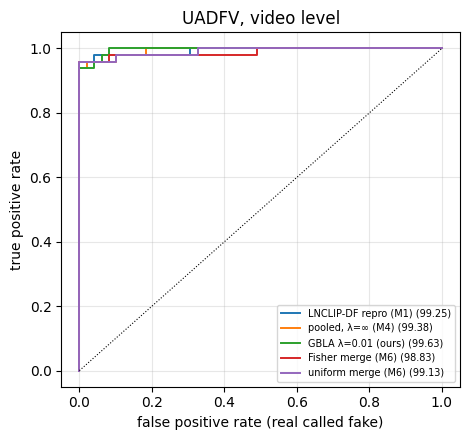

In [13]:
# 8.2 ROC curves (video level)
fig, ax = plt.subplots(figsize=(4.8, 4.5))
for k in MAIN + [k for k in ("fisher", "uniform") if k in MODELS]:
    fpr, tpr = roc_points(y_vid, VIDEO_SCORES[k])
    ax.plot(fpr, tpr, label=f"{MODELS[k][0]} ({100 * auc(y_vid, VIDEO_SCORES[k]):.2f})", lw=1.4)
ax.plot([0, 1], [0, 1], "k:", lw=0.8)
ax.set_xlabel("false positive rate (real called fake)"); ax.set_ylabel("true positive rate")
ax.set_title("UADFV, video level"); ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(M9B_DIR / "uadfv_roc.png", dpi=150); plt.show()

In [14]:
# 8.3 Summary
summary = {
    "protocol": "train FF++ c23 (DF, F2F, FS, NT), test UADFV 49 real + 49 fake, video AUC = mean frame prob",
    "parameters": param_report,
    "paper_gend_clip_uadfv_video_auc": PAPER_UADFV_VIDEO_AUC,
    "load_check": load_check.astype(str).to_dict("records"),
    "uadfv": main_table.drop(columns=["key"]).round(3).astype(str).to_dict("index"),
    "paired_differences_ours_minus": diffs.round(3).astype(str).to_dict("index"),
    "pair_check": pair_table.round(3).astype(str).to_dict("index"),
    "cross_dataset": cross.round(3).to_dict("index"),
    "sensitivity": sens.round(3).to_dict("index"),
    "bootstrap": f"{N_BOOT} pair-cluster resamples ({len(pairs)} real/fake pairs), seed {SEED}",
    "seeds_per_model": 1,
}
(M9B_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps({k: summary[k] for k in ("uadfv", "paired_differences_ours_minus")}, indent=1, ensure_ascii=False))

{
 "uadfv": {
  "LNCLIP-DF repro (M1)": {
   "video AUC": "99.25",
   "95% CI": "[97.46, 100.00]",
   "frame AUC": "97.858",
   "video AP": "99.398",
   "video EER": "4.082",
   "real acc": "95.918",
   "fake acc": "97.959"
  },
  "pooled, λ=∞ (M4)": {
   "video AUC": "99.375",
   "95% CI": "[98.08, 100.00]",
   "frame AUC": "97.961",
   "video AP": "99.448",
   "video EER": "4.082",
   "real acc": "93.878",
   "fake acc": "95.918"
  },
  "GBLA λ=1": {
   "video AUC": "99.334",
   "95% CI": "[98.00, 100.00]",
   "frame AUC": "98.012",
   "video AP": "99.411",
   "video EER": "4.082",
   "real acc": "85.714",
   "fake acc": "97.959"
  },
  "GBLA λ=0.1": {
   "video AUC": "99.5",
   "95% CI": "[98.33, 100.00]",
   "frame AUC": "98.011",
   "video AP": "99.557",
   "video EER": "4.082",
   "real acc": "93.878",
   "fake acc": "95.918"
  },
  "GBLA λ=0.01 (ours)": {
   "video AUC": "99.625",
   "95% CI": "[98.83, 100.00]",
   "frame AUC": "97.974",
   "video AP": "99.643",
   "video EER": 